# Caribu, 4: sensitivity analysis

**What you will learn:** rank the parameters by their effect on the light a canopy absorbs, first one at a time,
then all together by random sampling; see that the ranking depends on the model used.

**You need:** tutorials 2 and 3. **Run time:** about 1 minute.

A **sensitivity analysis** answers: *which parameters matter most for this output?* It tells which parameters need
an accurate measurement, and which can stay at their defaults.

The output here is the share of the PAR the canopy absorbs from 8 to 16 h on 21 June at Paris, with the sun:

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from openalea.caribu.simulation import parameters, simulate
from openalea.metafspm.scene.scenarios import variants


def absorbed_share(values):
    summary = simulate({"sun": True, **values}, hours=9, start_hour=8).summary
    return summary["PAR_absorbed"].sum() / summary["PARi"].sum()


reference = absorbed_share({})
print(f"with the defaults: {reference:.3f}")

with the defaults: 0.660


## 1. One at a time

Each parameter is changed by −10 % and +10 % around its default, the others kept at their defaults. The relative
change of the output is recorded. `variants(..., design="one_at_a_time")` (from metafspm) writes these changes: the
reference, then each value of each parameter alone. (The number of leaves, a whole number, is left out: 10 % of 4 leaves is not a
leaf.)

soil_reflectance      0.0000
plant_height         -0.0032
stem_width            0.0050
leaf_transmittance   -0.0112
leaf_reflectance     -0.0224
leaf_inclination     -0.0252
leaf_width            0.0812
leaf_length           0.0882
dtype: float64

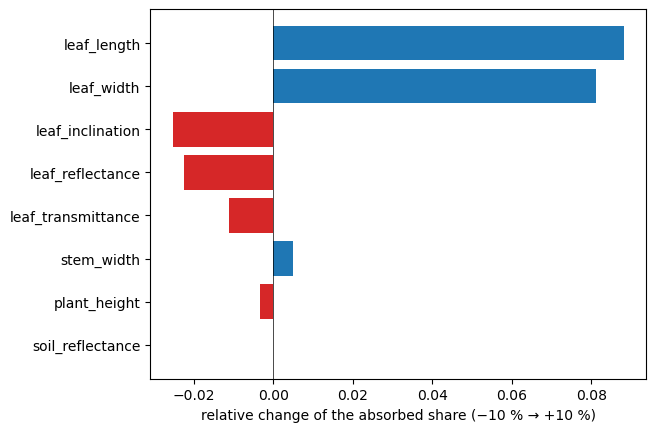

In [2]:
studied = ["leaf_length", "leaf_width", "leaf_inclination", "plant_height", "stem_width", "leaf_reflectance",
           "leaf_transmittance", "soil_reflectance"]
defaults = parameters().set_index("name")["value"]
changes = variants({}, {name: [0.9 * defaults[name], 1.1 * defaults[name]] for name in studied},
                   design="one_at_a_time")
shares = {label: absorbed_share(values) for label, values in changes.items() if label != "base"}
effects = {}
for name in studied:
    low, high = (shares[label] for label in shares if label.startswith(f"{name}="))
    effects[name] = (high - low) / reference
effects = pd.Series(effects).sort_values(key=abs)
plt.barh(effects.index, effects.values, color=np.where(effects.values >= 0, "tab:blue", "tab:red"))
plt.axvline(0, color="k", lw=0.5); plt.xlabel("relative change of the absorbed share (−10 % → +10 %)")
effects.round(4)

**Reading the bars.** A bar of 0.1 means the absorbed share changes by 10 % when the parameter goes from −10 % to
+10 %. Blue bars increase it, red ones decrease it.

- The leaf size (`leaf_length`, `leaf_width`) matters most: it sets the leaf area.
- The leaf angle comes next.
- The optics (`leaf_reflectance`, `leaf_transmittance`) lower the absorbed share: what a leaf reflects or transmits
  it does not absorb.
- `soil_reflectance` has no effect at all. The direct model ignores the light the soil sends back up.

## 2. The ranking depends on the model

With the nested model, the light scattered by the leaves and the soil is counted. The same analysis on the optics:

In [3]:
nested = {}
for name in ("leaf_reflectance", "leaf_transmittance", "soil_reflectance"):
    low = simulate({"mode": "nested", name: 0.9 * defaults[name]}, hours=1, start_hour=12).summary.iloc[0]
    high = simulate({"mode": "nested", name: 1.1 * defaults[name]}, hours=1, start_hour=12).summary.iloc[0]
    nested[name] = (high["absorbed_fraction"] - low["absorbed_fraction"]) / low["absorbed_fraction"]
pd.Series(nested).round(4)

leaf_reflectance     -0.0108
leaf_transmittance   -0.0045
soil_reflectance      0.0077
dtype: float64

With scattering, the soil's reflectance matters: the light it sends back up is partly absorbed by the leaves. The
leaves' optics matter less than in the direct model, since part of what a leaf passes on is absorbed by another. A
sensitivity analysis answers for a given model: before concluding that a parameter does not matter, check that the
model represents the process it acts on.

Caribu has no random part: the same parameters always give the same result. The plants' arrangement (here their
rotations) is fixed by `simulate`.

## 3. All together: random sampling

Changing one parameter at a time explores only a cross around the defaults. Here four parameters vary together, each
between −20 % and +20 % of its default. A **Latin hypercube** draws 32 combinations that cover each parameter's range
evenly (`variants(..., design="sampling")`, from metafspm). A linear regression on the standardised parameters gives **standardised regression coefficients** (SRC):

- the SRC of a parameter is the change of the output, in standard deviations, for a change of one standard deviation
  of the parameter;
- when the regression fits well (R² close to 1), the squared SRCs say which share of the output's variance each
  parameter explains.

Dedicated libraries (for example SALib) offer more methods (Morris, Sobol); the principle is the same.

In [4]:
sampled = ["leaf_width", "leaf_inclination", "leaf_reflectance", "leaf_transmittance"]
samples = variants({}, {n: (0.8 * defaults[n], 1.2 * defaults[n]) for n in sampled}, design="sampling", samples=32,
                   seed=0)
values = pd.DataFrame(list(samples.values()))[sampled]
output = np.array([absorbed_share(scenario) for scenario in samples.values()])

standardised = (values - values.mean()) / values.std()
design = np.column_stack([np.ones(len(values)), standardised.values])
y = (output - output.mean()) / output.std()
coefficients, *_ = np.linalg.lstsq(design, y, rcond=None)
r2 = 1 - np.sum((y - design @ coefficients) ** 2) / np.sum((y - y.mean()) ** 2)
print(pd.Series(coefficients[1:], index=sampled).round(2).to_string())
print(f"R2 = {r2:.3f}")

leaf_width            0.89
leaf_inclination     -0.29
leaf_reflectance     -0.25
leaf_transmittance   -0.12
R2 = 0.996


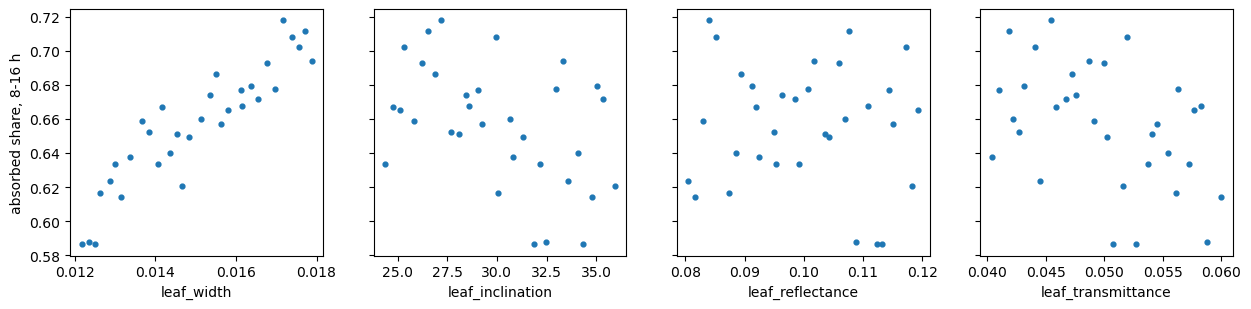

In [5]:
fig, axes = plt.subplots(1, len(sampled), figsize=(15, 3.2), sharey=True)
for ax, name in zip(axes, sampled):
    ax.scatter(values[name], output, s=12); ax.set_xlabel(name)
axes[0].set_ylabel("absorbed share, 8-16 h");

**Reading the result.** With R² close to 1, the linear regression explains nearly all the variation, and the SRCs
rank the parameters: the leaf width (the leaf area) first, then the leaf angle and the optics. The scatter plots
show the same: a clear trend for the most influential parameters, a cloud for the others.

## Try it yourself

1. Repeat the one-at-a-time analysis at noon only (`hours=1, start_hour=12`): does the leaf angle gain or lose
   importance? Why?
2. Add `plant_height` to the random sample. Where does it rank?
3. Run the one-at-a-time analysis with the nested model for all the parameters (a single hour, it is slower).

**Next:** `05_experimental_data.ipynb`.